# Streamflow forecasts from the NOAA National Water Model

The NOAA National Water Model (NWM) simulates and forecasts streamflow on every river reach of a national
stream network for the contiguous United States, and NOAA publishes its output as NetCDF files several
times a day. This notebook:

1. finds the newest complete 10-day ("medium-range") forecast from the 00 UTC run in the public archive,
2. maps the forecast flow on the larger rivers for one forecast hour,
3. finds the model reaches at five long-running USGS stream gauges and follows their forecast flow day by day,
4. runs the same per-file step over more forecast hours in parallel with Ray.

**Data**

* NWM operational output on the AWS Registry of Open Data, bucket `s3://noaa-nwm-pds`:
  <https://registry.opendata.aws/noaa-nwm-pds/>. NOAA describes the bucket as a rolling archive (when this notebook ran it held
  every day back to 1 January 2025), so the notebook picks the newest complete 00 UTC forecast rather than a fixed date, and the numbers change from run to run.
  The outputs committed here are from the forecast that started at 00 UTC on 9 November 2026 (reference time
  2026-11-09 00:00 UTC); a re-run picks the newest complete forecast instead.
* Reach locations and USGS gauge ids come from the NWM Retrospective v3.0 Zarr store,
  `s3://noaa-nwm-retrospective-3-0-pds`: <https://registry.opendata.aws/nwm-archive/>. Only its small per-reach
  coordinate arrays are read, not the multi-decade streamflow record.

**Model guidance, not the official river forecast.** The NWM is a model, and its forecasts are guidance. The
official river forecasts at gauges like these come from the National Weather Service's River Forecast Centers
(<https://water.noaa.gov>), and rivers whose flow is set by dam releases, such as the Columbia, are represented only
approximately. This notebook shows the forecast only and does not compare it with observed flow; observed flow is
available from the USGS (<https://waterdata.usgs.gov>) and, as the model's own input, in each day's `usgs_timeslices/`
folder in the same bucket.

**License and attribution.** The National Water Model is run by NOAA's National Weather Service. Its output is a
work of the U.S. Government, in the public domain, and NOAA Open Data Dissemination (NODD) data are free to use.
NOAA asks for attribution, does not allow stating or implying NOAA endorsement, and asks that modified data (such
as the plots here) not be presented as original NOAA data. Credit: NOAA National Water Model, via NODD on AWS.

**Requirements:** `pip install xarray h5netcdf s3fs zarr numpy pandas matplotlib ray`

All reads are anonymous; no cloud account is needed. One forecast file is about 13 MB. The main analysis
downloads a dozen of them plus about 20 MB of reach metadata (about 170 MB in all); the Ray section downloads
40 more (about 0.5 GB).

In [1]:
import io
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import s3fs
import xarray as xr

fs = s3fs.S3FileSystem(anon=True)  # anonymous access to the public buckets

FORECAST_BUCKET = "noaa-nwm-pds"
RETRO_CHRTOUT = "s3://noaa-nwm-retrospective-3-0-pds/CONUS/zarr/chrtout.zarr"

# USGS stream gauges to follow (site number -> station name). Any gauge that the
# NWM network routes through can be added here.
GAUGES = {
    "07289000": "Mississippi River at Vicksburg, MS",
    "03611500": "Ohio River at Metropolis, IL",
    "06934500": "Missouri River at Hermann, MO",
    "14105700": "Columbia River at The Dalles, OR",
    "11447650": "Sacramento River at Freeport, CA",
}

## 1. Find the newest complete 00 UTC forecast

Each day has a folder `nwm.YYYYMMDD/` with one sub-folder per model configuration. The medium-range forecast
(ensemble member 1) runs every six hours and writes one channel file per forecast hour, out to 240 hours (10 days),
named `nwm.tHHz.medium_range.channel_rt_1.fNNN.conus.nc`: `HH` is the hour (UTC) the run started and `NNN` the
forecast hour, from 001 to 240. This notebook uses the run that starts at 00 UTC (`CYCLE_HOUR = "00"`
below); set it to `"06"`, `"12"` or `"18"` to use one of the day's later runs instead.

Recent runs may still be uploading, so the function walks back from the newest day until it finds a run of
that cycle with all 240 files.

In [2]:
def find_latest_run(cycle_hour="00", n_hours=240, days_back=5):
    """Return (day, files) for the newest `cycle_hour` UTC medium-range run with all of its channel files."""
    days = sorted(p.rsplit("/", 1)[-1] for p in fs.ls(FORECAST_BUCKET) if "/nwm." in p)
    for day in reversed(days[-days_back:]):
        pattern = f"{FORECAST_BUCKET}/{day}/medium_range_mem1/nwm.t{cycle_hour}z.medium_range.channel_rt_1.f*.conus.nc"
        files = sorted(fs.glob(pattern))
        if len(files) == n_hours:
            return day, files
    raise RuntimeError(f"no complete {cycle_hour}z medium-range run in the last {days_back} days")


CYCLE_HOUR = "00"  # hour (UTC) the run starts: "00", "06", "12" or "18"
run_day, files = find_latest_run(CYCLE_HOUR)
n_days = sum("/nwm." in p for p in fs.ls(FORECAST_BUCKET))  # same filter as in find_latest_run
print(f"archive holds {n_days} day folders; using the {run_day.removeprefix('nwm.')} {CYCLE_HOUR} UTC run")
print(f"{len(files)} hourly channel files, e.g. {files[0].rsplit('/', 1)[-1]}")
print(f"one file is {fs.size(files[0]) / 1e6:.1f} MB")

archive holds 678 day folders; using the 20261109 00 UTC run
240 hourly channel files, e.g. nwm.t00z.medium_range.channel_rt_1.f001.conus.nc
one file is 12.7 MB


## 2. Reach locations and gauges

The forecast files identify reaches only by `feature_id`. The retrospective Zarr store uses the same reach
network and carries each reach's latitude, longitude and, where there is one, the USGS gauge id. These
coordinate arrays are stored as single chunks, so loading them is a few quick downloads.

In [3]:
t0 = time.time()
retro = xr.open_zarr(RETRO_CHRTOUT, storage_options={"anon": True}, chunks=None)  # plain lazy arrays, no dask
reaches = pd.DataFrame(
    {
        "latitude": retro["latitude"].values,
        "longitude": retro["longitude"].values,
        "gage_id": np.char.strip(retro["gage_id"].values.astype(str)),
    },
    index=pd.Index(retro["feature_id"].values, name="feature_id"),
)
print(f"{len(reaches):,} reaches, {(reaches['gage_id'] != '').sum():,} of them at a USGS gauge "
      f"(loaded in {time.time() - t0:.1f} s)")

gauges = reaches[reaches["gage_id"].isin(list(GAUGES))].reset_index().set_index("gage_id")
missing = set(GAUGES) - set(gauges.index)
assert not missing, f"gauges not found in the NWM network: {missing}"
gauges = gauges.loc[list(GAUGES)]
gauges["name"] = [GAUGES[g] for g in gauges.index]
gauge_reaches = gauges["feature_id"].to_dict()  # gauge id -> NWM feature_id
gauges

2,776,734 reaches, 8,660 of them at a USGS gauge (loaded in 21.6 s)


,feature_id,latitude,longitude,name
gage_id,,,,
07289000,19266232,32.274517,-90.955315,"Mississippi River at Vicksburg, MS"
03611500,1840025,37.140961,-88.734444,"Ohio River at Metropolis, IL"
06934500,6013072,38.709599,-91.439293,"Missouri River at Hermann, MO"
14105700,947070191,45.604904,-121.167641,"Columbia River at The Dalles, OR"
11447650,15048349,38.474285,-121.522270,"Sacramento River at Freeport, CA"


## 3. The per-file step

Both functions download one forecast file into memory (about 13 MB) and open it with xarray. `gauge_flows` is
the step that later runs once per file: it returns the forecast streamflow, in cubic metres per second, at the
chosen reaches for that file's forecast hour. It creates its own S3 client so that it can also run inside a
Ray worker process.

In [4]:
def open_forecast(path):
    """Download one NWM channel file and open it from memory."""
    data = s3fs.S3FileSystem(anon=True).cat_file(path)
    return xr.open_dataset(io.BytesIO(data), engine="h5netcdf")


def gauge_flows(path, reach_ids):
    """Forecast streamflow (m3/s) at the given reaches for one forecast hour.

    reach_ids maps a label (here the USGS gauge id) to an NWM feature_id.
    """
    with open_forecast(path) as ds:
        q = ds["streamflow"].sel(feature_id=list(reach_ids.values())).values
        valid_time = pd.Timestamp(ds["time"].values[0])
    return {"valid_time": valid_time, **{label: float(v) for label, v in zip(reach_ids, q)}}


print(gauge_flows(files[23], gauge_reaches))

{'valid_time': Timestamp('2026-11-10 00:00:00'), '07289000': 7436.6098337788135, '03611500': 2291.0399487912655, '06934500': 2822.2199369184673, '14105700': 2644.3499408941716, '11447650': 253.77999432757497}


## 4. Map one forecast hour

Read the whole `streamflow` variable from the forecast hour 24 file, join it to the reach locations and plot the
reaches that carry at least 10 m³/s. Dot colour and size follow the flow on a log scale; the triangles are the
five gauges.

2,776,734 reaches in the file, 2,709,580 with a value
reaches above 10 m3/s: 72,187; above 1,000 m3/s: 2,201


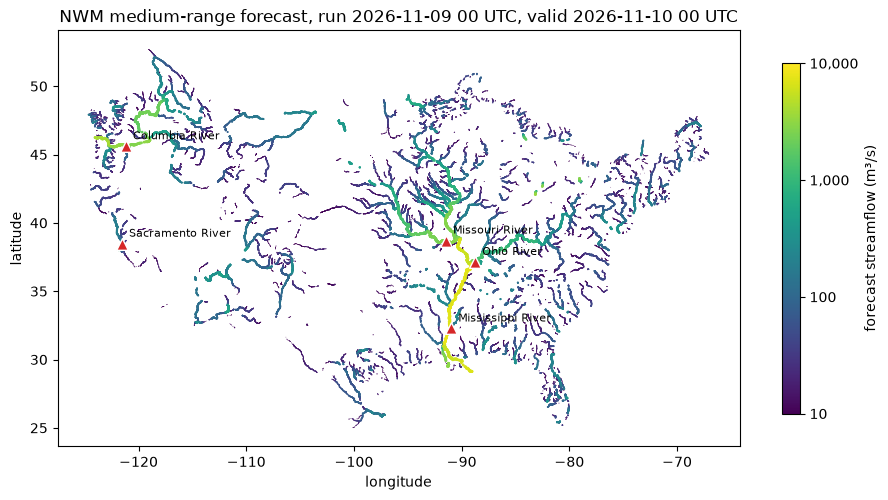

In [5]:
with open_forecast(files[23]) as ds:
    flow = ds["streamflow"].to_series()
    map_time = pd.Timestamp(ds["time"].values[0])
    run_time = pd.Timestamp(ds["reference_time"].values[0])

print(f"{flow.size:,} reaches in the file, {flow.notna().sum():,} with a value")
print(f"reaches above 10 m3/s: {(flow >= 10).sum():,}; above 1,000 m3/s: {(flow >= 1000).sum():,}")

big = reaches.join(flow.rename("streamflow"), how="inner")
big = big[big["streamflow"] >= 10].sort_values("streamflow")
logq = np.log10(big["streamflow"])

fig, ax = plt.subplots(figsize=(11, 6.5))
sc = ax.scatter(big["longitude"], big["latitude"], c=logq, s=0.2 + 1.5 * (logq - 1),
                cmap="viridis", vmin=1, vmax=4, linewidths=0, rasterized=True)
ax.scatter(gauges["longitude"], gauges["latitude"], marker="^", s=70, color="tab:red", edgecolor="white", zorder=3)
for gid, row in gauges.iterrows():
    ax.annotate(row["name"].split(" at ")[0], (row["longitude"], row["latitude"]),
                xytext=(5, 5), textcoords="offset points", fontsize=8)
cb = fig.colorbar(sc, ax=ax, shrink=0.7, ticks=[1, 2, 3, 4])
cb.ax.set_yticklabels(["10", "100", "1,000", "10,000"])
cb.set_label("forecast streamflow (m³/s)")
ax.set_aspect(1 / np.cos(np.deg2rad(38)))
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title(f"NWM medium-range forecast, run {run_time:%Y-%m-%d %H} UTC, valid {map_time:%Y-%m-%d %H} UTC")
plt.show()

## 5. Forecast flow at the gauges, one file per day

Run the per-file step on forecast hours 24, 48, ..., 240: ten files, one after another. The gauges sit on rivers
of very different size, so each gets its own panel.

In [6]:
daily_files = files[23::24]  # forecast hours 24, 48, ..., 240

t0 = time.time()
daily = pd.DataFrame([gauge_flows(p, gauge_reaches) for p in daily_files]).set_index("valid_time")
serial_seconds = time.time() - t0
print(f"{len(daily_files)} files read one after another in {serial_seconds:.0f} s "
      f"({serial_seconds / len(daily_files):.1f} s per file)")
daily.round(1)

10 files read one after another in 11 s (1.1 s per file)


,07289000,03611500,06934500,14105700,11447650
valid_time,,,,,
2026-11-10,7436.6,2291.0,2822.2,2644.3,253.8
2026-11-11,7364.7,2094.5,2487.5,2776.9,240.2
2026-11-12,7471.3,2027.3,2448.6,2871.7,238.4
2026-11-13,7588.0,2010.4,2522.6,2957.6,249.3
2026-11-14,7672.4,2006.0,2341.8,3001.9,272.9
2026-11-15,7751.7,1998.6,2202.5,2990.0,297.5
2026-11-16,7828.9,1993.0,2222.6,2934.1,311.4
2026-11-17,7971.7,1985.9,2312.8,2863.2,316.3
2026-11-18,8105.8,1975.8,2257.6,2803.2,316.0


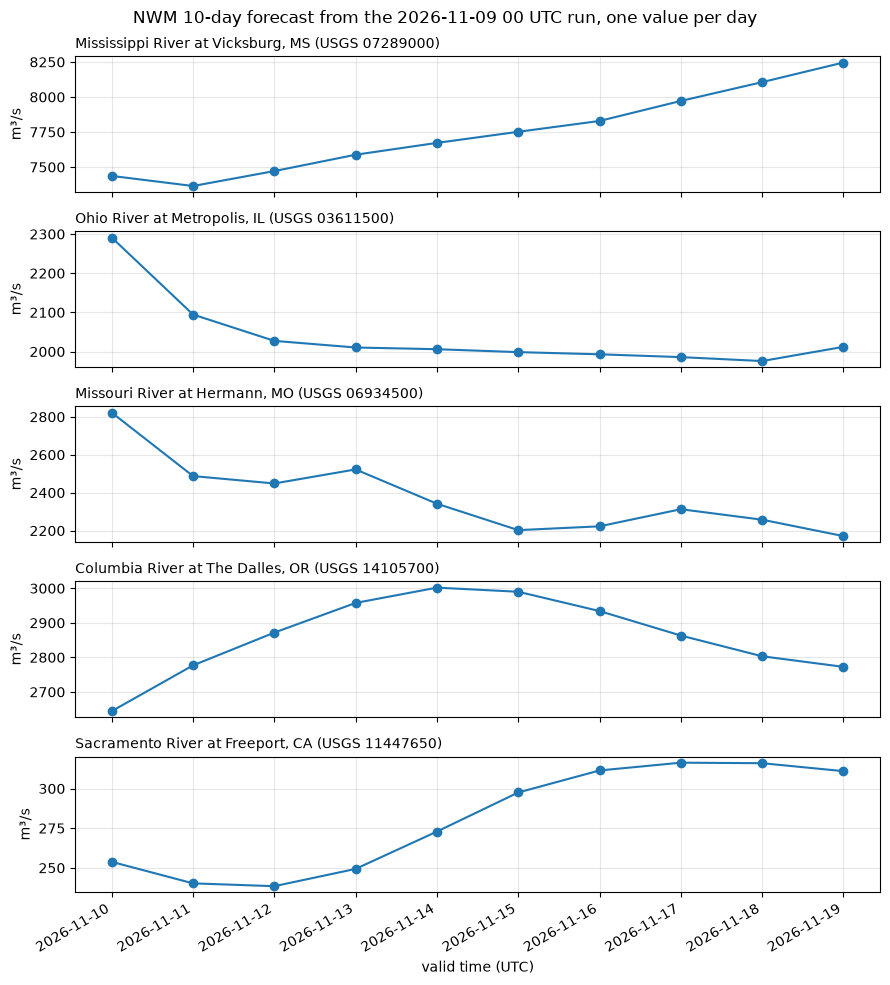

change over the forecast, day 1 to day 10 (%):
Mississippi River at Vicksburg, MS    10.9
Ohio River at Metropolis, IL         -12.2
Missouri River at Hermann, MO        -23.1
Columbia River at The Dalles, OR       4.8
Sacramento River at Freeport, CA      22.5


In [7]:
fig, axes = plt.subplots(len(GAUGES), 1, figsize=(9, 10), sharex=True)
for ax, (gid, name) in zip(axes, GAUGES.items()):
    ax.plot(daily.index, daily[gid], "o-", color="tab:blue")
    ax.set_title(f"{name} (USGS {gid})", fontsize=10, loc="left")
    ax.set_ylabel("m³/s")
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("valid time (UTC)")
fig.suptitle(f"NWM 10-day forecast from the {run_time:%Y-%m-%d %H} UTC run, one value per day")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

change = 100 * (daily.iloc[-1] / daily.iloc[0] - 1)
print("change over the forecast, day 1 to day 10 (%):")
print(change.rename(GAUGES).round(1).to_string())

## Scaling out with Ray

The per-file step is independent for each file, so it parallelises directly: wrap `gauge_flows` as a Ray task
and submit one task per file. Each task downloads and reads its own file, so the files never pass through the
driver; only a few numbers per file come back.

`ray.init(num_cpus=4)` starts a small local Ray instance. On a Ray cluster, `ray.init()` (or `ray.init(address=...)`)
connects to it instead and the same code spreads the tasks over its nodes. `STEP_HOURS = 6` reads every sixth
forecast hour (40 files, about 0.5 GB); `STEP_HOURS = 1` reads all 240.

In [8]:
import ray

ray.init(num_cpus=4)

STEP_HOURS = 6
ray_files = files[STEP_HOURS - 1::STEP_HOURS]

remote_gauge_flows = ray.remote(gauge_flows)

t0 = time.time()
refs = [remote_gauge_flows.remote(p, gauge_reaches) for p in ray_files]
fine = pd.DataFrame(ray.get(refs)).set_index("valid_time").sort_index()
ray_seconds = time.time() - t0
print(f"{len(ray_files)} files read by Ray tasks on 4 CPUs in {ray_seconds:.0f} s "
      f"({ray_seconds / len(ray_files):.1f} s per file, versus {serial_seconds / len(daily_files):.1f} s one by one)")

40 files read by Ray tasks on 4 CPUs in 22 s (0.6 s per file, versus 1.1 s one by one)


_The Ray figure is wall-clock time divided by the number of files, that is throughput with four workers; the one-by-one figure is the average time per file when they are read one after another. These timings come from one run on a shared machine. The reads are network-bound, so the numbers change with the network and the machine's load; they are not a benchmark._

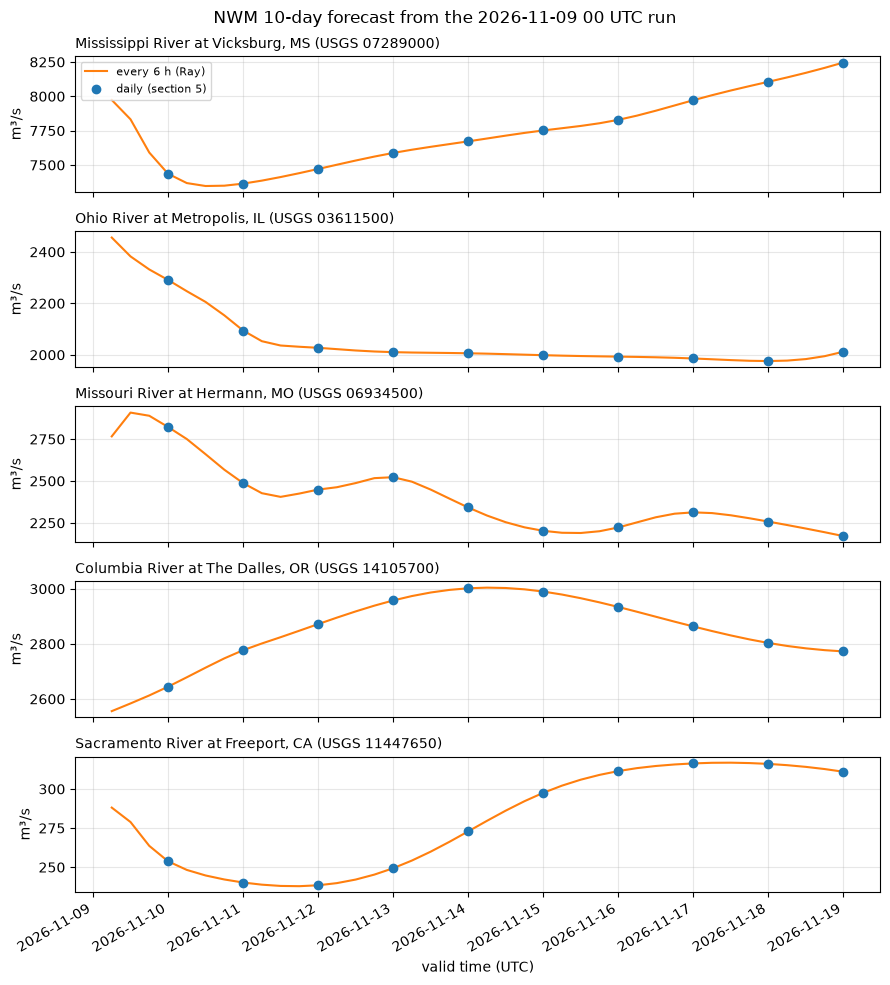

In [9]:
fig, axes = plt.subplots(len(GAUGES), 1, figsize=(9, 10), sharex=True)
for ax, (gid, name) in zip(axes, GAUGES.items()):
    ax.plot(fine.index, fine[gid], "-", color="tab:orange", label=f"every {STEP_HOURS} h (Ray)")
    ax.plot(daily.index, daily[gid], "o", color="tab:blue", label="daily (section 5)")
    ax.set_title(f"{name} (USGS {gid})", fontsize=10, loc="left")
    ax.set_ylabel("m³/s")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
axes[-1].set_xlabel("valid time (UTC)")
fig.suptitle(f"NWM 10-day forecast from the {run_time:%Y-%m-%d %H} UTC run")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

# The daily values are a subset of the finer series, so the two must agree exactly.
common = daily.index.intersection(fine.index)
assert np.allclose(daily.loc[common], fine.loc[common])

In [10]:
ray.shutdown()